# 1: Análisis Exploratorio y ANOVA

1. Carga del dataset


In [8]:
import pandas as pd
import numpy as np


df = pd.read_csv("datos_logistica_transporte.csv", encoding="latin1")
df["Tipo_Ruta"] = df["Tipo_Ruta"].replace("Monta¤a", "Montaña")
print(df.head())
print("Dimensiones:", df.shape)
print(df.isnull().sum())

   ID_Viaje  Tipo_Ruta  Peso_Carga_Ton  Velocidad_Promedio_kmh  Consumo_Litros
0         1  Autopista           27.27                    89.4            54.0
1         2    Montaña           22.60                    52.7            79.2
2         3    Montaña           26.55                    50.3            87.9
3         4  Autopista           25.48                   102.7            54.9
4         5     Urbana           18.35                    43.2            52.6
Dimensiones: (50, 5)
ID_Viaje                  0
Tipo_Ruta                 0
Peso_Carga_Ton            0
Velocidad_Promedio_kmh    0
Consumo_Litros            0
dtype: int64


2. Medidas de tendencia central y dispersion

In [9]:

variables = [
    "Peso_Carga_Ton",
    "Velocidad_Promedio_kmh",
    "Consumo_Litros"
]

datos = df[variables]

estadisticas = pd.DataFrame({
    "Media": datos.mean(),
    "Mediana": datos.median(),
    "Moda": datos.mode().iloc[0],
    "Varianza": datos.var(),
    "Desviación estándar": datos.std(),
    "Mínimo": datos.min(),
    "Máximo": datos.max(),
    "Rango": datos.max() - datos.min(),
    "Q1": datos.quantile(0.25),
    "Q3": datos.quantile(0.75),
    "CV (%)": (datos.std() / datos.mean()) * 100
})

print(estadisticas.round(2))


                        Media  Mediana   Moda  Varianza  Desviación estándar  \
Peso_Carga_Ton          15.41    15.60   4.11     51.05                 7.15   
Velocidad_Promedio_kmh  56.56    45.45  97.70    731.52                27.05   
Consumo_Litros          51.13    42.55  36.60    361.40                19.01   

                        Mínimo  Máximo  Rango     Q1     Q3  CV (%)  
Peso_Carga_Ton            4.11   27.28  23.17   8.86  20.65   46.37  
Velocidad_Promedio_kmh   20.40  104.50  84.10  38.72  85.20   47.82  
Consumo_Litros           27.20   90.40  63.20  38.30  56.02   37.18  


In [10]:

estadisticas_ruta = df.groupby("Tipo_Ruta")["Consumo_Litros"].agg(
    ["count", "mean", "median", "var", "std", "min", "max"]
)
estadisticas_ruta["Rango"] = (
    estadisticas_ruta["max"] - estadisticas_ruta["min"]
)

print(estadisticas_ruta.round(2))


           count   mean  median     var    std   min   max  Rango
Tipo_Ruta                                                        
Autopista     15  41.25    41.3   52.03   7.21  27.3  54.9   27.6
Montaña       14  75.01    81.8  307.41  17.53  40.3  90.4   50.1
Urbana        21  42.27    38.9   94.23   9.71  27.2  63.3   36.1


In [ ]:
estadisticas_ruta = df.groupby("Tipo_Ruta")["Velocidad_Promedio_kmh"].agg(
    ["count", "mean", "median", "var", "std", "min", "max"]
)
estadisticas_ruta["Rango"] = (
    estadisticas_ruta["max"] - estadisticas_ruta["min"]
)

print(estadisticas_ruta.round(2))


           count   mean  median    var   std   min    max  Rango
Tipo_Ruta                                                       
Autopista     15  94.84   96.50  57.18  7.56  80.4  104.5   24.1
Montaña       14  49.70   50.25  27.68  5.26  42.0   60.4   18.4
Urbana        21  33.80   35.80  58.10  7.62  20.4   43.2   22.8


In [12]:
estadisticas_ruta = df.groupby("Tipo_Ruta")["Peso_Carga_Ton"].agg(
    ["count", "mean", "median", "var", "std", "min", "max"]
)
estadisticas_ruta["Rango"] = (
    estadisticas_ruta["max"] - estadisticas_ruta["min"]
)

print(estadisticas_ruta.round(2))


           count   mean  median    var   std   min    max  Rango
Tipo_Ruta                                                       
Autopista     15  16.15   16.38  29.32  5.41  5.60  27.27  21.67
Montaña       14  20.32   23.12  59.42  7.71  4.80  27.28  22.48
Urbana        21  11.61    9.08  33.52  5.79  4.11  26.01  21.90


In [55]:
df["Litros_por_Tonelada"] = (df["Consumo_Litros"] / df["Peso_Carga_Ton"])
tabla = df.groupby("Tipo_Ruta")["Litros_por_Tonelada"].mean().reset_index()
tabla.columns = ["Tipo de ruta", "Litros por tonelada"]
display(tabla.round(2))


,Tipo de ruta,Litros por tonelada
0,Autopista,2.74
1,Montaña,4.20
2,Urbana,4.14


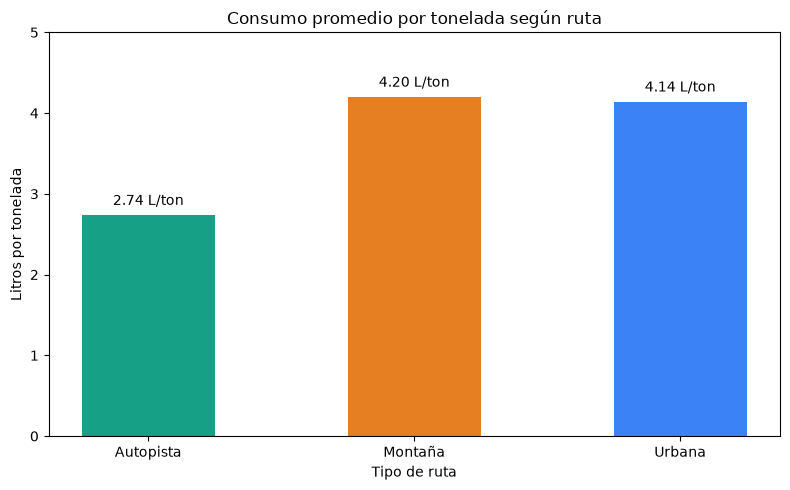

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

barras = plt.bar(
    tabla["Tipo de ruta"],
    tabla["Litros por tonelada"],
    color=["#16A085", "#E67E22", "#3B82F6"],
    width=0.5
)

plt.bar_label(barras, fmt="%.2f L/ton", padding=5)

plt.xlabel("Tipo de ruta")
plt.ylabel("Litros por tonelada")
plt.title("Consumo promedio por tonelada según ruta")

plt.ylim(0, 5)
plt.tight_layout()
plt.show()


Conclusiones iniciales.
- En promedio las rutas que se realizan en montaña tienen un consumo de combustible mucho mayor que cuando se realiza en ciudad o en autopista, estas dos ultimas tienen un rendimiento de combustible muy parecido.
- La velocidad promedio es mucho mayor en la autopista, seguido de la velocidad promedio en la montaña y por ultimo en la ciudad, esto puede ser debido a los altos y semaforos que tenga la ciudad asi como los limites de velocidad establecidos.
- El promedio del peso de carga que tienen las rutas realizadas son mayores en montaña, seguido de las que se realizan en autopista y por utlimo las que se realizan en la ciudad.
- En promedio el desempeño que tienen las rutas de litros consumidos por tonelada de carga en montaña y en rutas urbanas es casi igual, siendo muy superios cuando se realiza en autopista.

3. Prueba de hipotesis ANOVA.

In [13]:
from scipy.stats import f_oneway
import pandas as pd

alpha = 0.05

variables = [
    "Consumo_Litros",
    "Peso_Carga_Ton",
    "Velocidad_Promedio_kmh"
]

for variable in variables:

    urbana = df[df["Tipo_Ruta"] == "Urbana"][variable]
    autopista = df[df["Tipo_Ruta"] == "Autopista"][variable]
    montana = df[df["Tipo_Ruta"] == "Montaña"][variable]

    F, p_value = f_oneway(urbana, autopista, montana)

    print("\nANOVA:", variable)
    print("F calculada:", F)
    print("Valor-p:", p_value)

    if p_value < alpha:
        print("Se rechaza H0")
        print("Existen diferencias significativas entre las rutas.")
    else:
        print("No se rechaza H0")
        print("No existe evidencia suficiente de diferencias significativas.")



ANOVA: Consumo_Litros
F calculada: 39.46504987531819
Valor-p: 8.734846920450398e-11
Se rechaza H0
Existen diferencias significativas entre las rutas.

ANOVA: Peso_Carga_Ton
F calculada: 8.21870533519798
Valor-p: 0.0008693239257238491
Se rechaza H0
Existen diferencias significativas entre las rutas.

ANOVA: Velocidad_Promedio_kmh
F calculada: 339.21313620819006
Valor-p: 1.1758653085832788e-28
Se rechaza H0
Existen diferencias significativas entre las rutas.


Conclusiones ANOVA.
- Con esta tecnica estadistica de ANOVA, podemos comprobar que estadistticamente con un nivel de significancia del 5%, existen diferencias significativas entre el consumo de combustible, el peso de carga y la velocidad promedio de las tres diferentes rutas, tas y como lo habiamos planteado previamente en el analisis anterior. El valor de P es mucho menor al nivel de significancia previemante establecido por tal motivo se rechaza la hipotesis nula.

#  2: Analisis de correlacion

1. Matriz de correlacion de Pearson

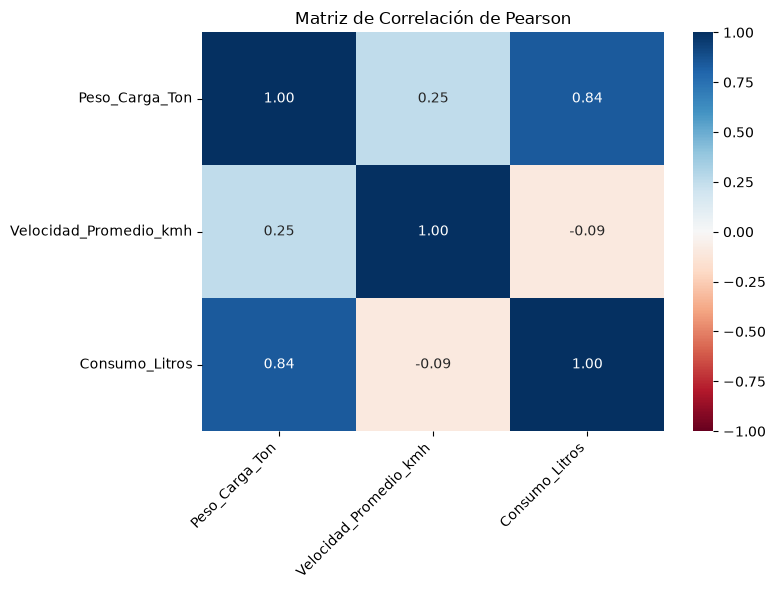

In [18]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

variables = [
    "Peso_Carga_Ton",
    "Velocidad_Promedio_kmh",
    "Consumo_Litros"
]
correlacion = df[variables].corr(method="pearson")

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Matriz de Correlación de Pearson")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


- Analisis de resultados.
En esta matri de confusion, se puede observar que el consumo de litros tiene una correlacion muy fuerte con el peso de la carga en toneladas con una correlacion r de .84, por otro lado la correlacion qu eexiste con la velocidad promedio es casi inexistente con una correlacion r de -.09. Recordando que un valor cercano a 1 o -1 indicaria una correlacion fuert ya sea positiva o negativa. Como el valor es positivo se puede concluir que entre mas peso esta transportando la ruta consumira mas litros de gasolina.

# 3: Regresión Lineal Múltiple

1. Ajuste del modelo

Y = β₀ + β₁X₁ + β₂X₂.

- Y: Consumo de combustible estimado (litros).
- β₀: Intercepto del modelo.
- β₁: Coeficiente del peso de carga.
- β₂: Coeficiente de la velocidad promedio.
- X₁: Peso de carga (toneladas).
- X₂: Velocidad promedio (km/h).

In [26]:
X1 = df["Peso_Carga_Ton"].to_numpy()
X2 = df["Velocidad_Promedio_kmh"].to_numpy()
Y = df["Consumo_Litros"].to_numpy()

media_X1 = np.mean(X1)
media_X2 = np.mean(X2)
media_Y = np.mean(Y)

print("Media X1:", media_X1)
print("Media X2:", media_X2)
print("Media Y:", media_Y)


Media X1: 15.409600000000001
Media X2: 56.562
Media Y: 51.132


In [29]:

s1 = np.sum((X1 - media_X1)**2)
s2 = np.sum((X2 - media_X2)**2)
s3 = np.sum((X1 - media_X1) * (X2 - media_X2))
s4 = np.sum((X1 - media_X1) * (Y - media_Y))
s5 = np.sum((X2 - media_X2) * (Y - media_Y))

print("S1:", s1)
print("S2:", s2)
print("S3:", s3)
print("S4:", s4)
print("S5:", s5)


S1: 2501.577992
S2: 35844.4778
S3: 2375.79724
S4: 5609.64964
S5: -2365.1092


- B1 = ((s4 * s2) - (s5 * s3)) / ((s1 * s2) - s3**2)
- B2 = ((s5 * s1) - (s4 * s3)) / ((s1 * s2) - s3**2)
- B0 = media_Y - B1 * media_X1 - B2 * media_X2

In [32]:
B1 = (s4 * s2 - s5 * s3) / (s1 * s2 - s3**2)
B2 = (s5 * s1 - s4 * s3) / (s1 * s2 - s3**2)
B0 = media_Y - B1 * media_X1 - B2 * media_X2
print("B0:", B0)
print("B1:", B1)
print("B2:", B2)

B0: 26.17942999560625
B1: 2.459958999290962
B2: -0.22903034176797601


In [ ]:
Y_pred = B0 + B1 * X1 + B2 * X2
residuales = Y - Y_pred
MSE = np.mean(residuales**2)
RMSE = np.sqrt(MSE)
SS_res = np.sum(residuales**2)           #suma de cuadrados de los residuos
SS_total = np.sum((Y - np.mean(Y))**2)   #suma de cuadrados totales
R2 = 1 - (SS_res / SS_total)

print("MSE:", MSE)
print("RMSE:", RMSE)
print("R²:", R2)


MSE: 67.34957833636221
RMSE: 8.2066788859052
R²: 0.8098400870867204


- Validar la significancia de los coeficientes (Valor-P < 0.05).

Formulas necesarias para calcular el valor de P
 - MSE_residual = SS_res / gl
 - SE_B1 = sqrt((MSE_residual * s2) / ((s1 * s2) - s3**2))    #Error estandar B1
 - SE_B2 = sqrt((MSE_residual * s1) / ((s1 * s2) - s3**2))    #Error estandar B2
 - t_B1 = B1 / SE_B1
 - t_B2 = B2 / SE_B2
 - t_critica = (1 - alpha / 2, gl)




In [50]:
from scipy.stats import t
alpha = 0.05
n = 50
gl = n - 3
MSE_residual = SS_res / gl 

SE_B1 = np.sqrt(MSE_residual * s2 / ((s1 * s2) - s3**2))    
SE_B2 = np.sqrt(MSE_residual * s1 / ((s1 * s2) - s3**2))
t_B1 = B1 / SE_B1
t_B2 = B2 / SE_B2
t_critica = t.ppf(1 - alpha / 2, gl)

print("t crítica:", t_critica)

print("\nB1 - Peso de carga")
print("t calculada:", t_B1)

if -t_critica < t_B1 < t_critica:
    print("No se rechaza H0")
else:
    print("Se rechaza H0.\nEl peso de carga presenta una asociación estadísticamente significativa con el consumo de combustible, manteniendo constante la velocidad promedio.")

print("\nB2 - Velocidad promedio")
print("t calculada:", t_B2)

if -t_critica < t_B2 < t_critica:
    print("No se rechaza H0")
else:
    print("Se rechaza H0.\nLa velocidad promedio presenta una asociación estadísticamente significativa con el consumo de combustible, manteniendo constante el peso de carga.")



t crítica: 2.0117405137297655

B1 - Peso de carga
t calculada: 14.070619135774894
Se rechaza H0.
El peso de carga presenta una asociación estadísticamente significativa con el consumo de combustible, manteniendo constante la velocidad promedio.

B2 - Velocidad promedio
t calculada: -4.958867056179308
Se rechaza H0.
La velocidad promedio presenta una asociación estadísticamente significativa con el consumo de combustible, manteniendo constante el peso de carga.


* Conlusiones.

Con base en los resultados ed la prueba t de Student para evaluar la significancia estadística , utilizando un nivel de significancia de 0.05 y 47 grados de libertad.mEl valor crítico obtenido fue de ±2.0117. Para el peso de carga (B1), se obtuvo un estadístico t de 14.0706, mientras que para la velocidad promedio (B2) se obtuvo un estadístico t de −4.9589.

Debido a que ambos estadísticos superan el valor crítico en términos absolutos, se rechazan las respectivas hipótesis nulas. Por lo tanto, se concluye que tanto el peso de carga como la velocidad promedio presentan tienen una relación estadísticamente significativa con el consumo de combustible

# 3: Toma de Decisiones

- ¿Debería la empresa evitar ciertas rutas para cargas pesadas?
- ¿En qué tipo de ruta se gasta más combustible y si la diferencia es estadísticamente significativa?
- Si la empresa quiere reducir el consumo, ¿debería enfocarse más en controlar la velocidad o en reducir el peso de carga? (Basado en los coeficientes deregresión).
- Utilizando la ecuación obtenida, pronostica el consumo para un camión con 15toneladas viajando a 80 km/h.

1. Si, ya que los resultados obtenidos previamente sugieren que las rutas en montañas son las que mas gasolina utilizan, pero tambien debido a que son las que en promedio son las que mas carga tienen, en promedio el consumo de gasolina que existe en rutas urbanas y rutas en montaña son practicamente iguales, la que si tiene un mucho menor consumo de combustible es la que se realiza en autopisa.
2. Por mucho la ruta que mas combustible gasta es la ruta que se realiza en la montaña, sin embargo esto tambien se debe principalmente a la cantidad de carga que lleva, en ciudad se gasta en promedio una cantidad inferior, pero haciendo una comparacion entre las toneladas de carga y los litros de gasolina consumidos el rendimiento es casi identico.
3. Los resultados sugieren que el peso de carga es un factor especialmente importante para el consumo de combustible ya que con nuestros resultados de matriz de correlacion de Pearson, tiene un valor mucho mas cercano a 1 en comparacion con la velocidad promedio

In [52]:
peso = 15
velocidad = 80

consumo_estimado = B0 + B1 * peso + B2 * velocidad

tabla = pd.DataFrame({
    "Peso (ton)": [peso],
    "Velocidad (km/h)": [velocidad],
    "Consumo estimado (L)": [round(consumo_estimado, 2)]
})
display(tabla)

,Peso (ton),Velocidad (km/h),Consumo estimado (L)
0,15,80,44.76


# Conclusiones finales.

El análisis permitió identificar que el consumo de combustible está asociado significativamente con el peso de carga y la velocidad promedio, además de presentar diferencias según el tipo de ruta.

Uno de los hallazgos más relevantes fue que las rutas de montaña y urbanas presentan consumos por tonelada muy similares, a pesar de sus diferencias en el consumo total. Esto demuestra la importancia de considerar la cantidad de carga transportada antes de atribuir un mayor gasto exclusivamente al tipo de ruta.

En consecuencia, FastTrack Logistics debería adoptar un enfoque de optimización que considere conjuntamente el peso, la velocidad y las condiciones de operación, evitando tomar decisiones basadas únicamente en el consumo total de combustible.